In [43]:

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

import matplotlib as mpl
plt.style.use("ggplot")
plt.rcParams["figure.dpi"] = 100
font = {"family": "sans-serif", "size": 12}

mpl.rc("font", **font)

from IPython.display import Image

In [44]:
df = pd.read_csv('train.csv')

Problem Statement -

A wind farm operator wants to monitor and predict the efficiency of wind turbines using sensor data collected from turbines.

In [45]:
df

,timestamp,active_power_calculated_by_converter,active_power_raw,ambient_temperature,generator_speed,generator_winding_temp_max,grid_power10min_average,nc1_inside_temp,nacelle_temp,reactice_power_calculated_by_converter,reactive_power,wind_direction_raw,wind_speed_raw,wind_speed_turbulence,turbine_id,Target
0,2021-02-19 20:18:00,816.636759,834.917206,31.694380,1159.616602,65.954214,917.897085,31.881972,31.504713,141.457644,165.501518,280.864782,7.057000,0.544082,Turbine_108,47.582787
1,2021-04-27 04:55:00,419.107829,421.050873,12.894948,928.747996,59.571319,445.554250,32.423705,32.755770,89.186457,113.835236,299.552460,5.474937,0.469031,Turbine_18,46.070328
2,2021-01-25 06:26:00,1303.530558,1337.566142,16.648388,1201.219775,61.270498,1364.716003,11.446849,18.332985,230.622309,281.452253,84.960106,8.092457,0.622318,Turbine_105,39.989236
3,2021-10-30 03:47:00,61.494872,53.481008,28.388141,769.806122,40.674348,14.324897,34.253204,32.662889,66.211015,75.017531,87.261119,4.071032,0.760719,Turbine_15,46.056587
4,2021-03-15 00:39:00,593.514364,611.659108,31.519527,1046.916768,64.341763,599.020172,32.405586,31.466387,137.163938,160.202421,313.724818,6.357943,0.346068,Turbine_01,54.346095
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
909599,2021-04-25 19:12:00,929.101908,948.441905,32.736076,1187.303192,83.187140,1343.320577,32.291391,35.152280,152.216446,191.088800,189.901812,7.155343,1.028960,Turbine_13,50.768675
909600,2021-02-20 17:37:00,100.730526,88.694599,30.540500,770.245593,56.235497,177.620552,30.434302,29.932141,85.353107,96.621675,93.417590,4.121607,0.595874,Turbine_158,44.234821
909601,2021-10-22 14:18:00,1120.915965,1165.016907,30.901129,1170.456860,62.942943,873.414622,30.491818,33.085164,42.820210,74.111173,230.988398,8.551669,0.951241,Turbine_15,46.942486
909602,2021-02-08 22:03:00,123.444564,116.066919,32.697933,770.190796,57.245207,95.865704,32.338824,31.525384,86.549094,97.470984,65.408801,4.324064,0.247335,Turbine_97,46.392221


In [46]:
df.shape

(909604, 16)

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df.isnull().sum()

timestamp                                 0
active_power_calculated_by_converter      0
active_power_raw                          0
ambient_temperature                       0
generator_speed                           0
generator_winding_temp_max                0
grid_power10min_average                   0
nc1_inside_temp                           0
nacelle_temp                              0
reactice_power_calculated_by_converter    0
reactive_power                            0
wind_direction_raw                        0
wind_speed_raw                            0
wind_speed_turbulence                     0
turbine_id                                0
Target                                    0
dtype: int64

In [49]:
df_1 = df.copy()

In [50]:
#df_1.drop(columns=['turbine_id'],inplace=True)

In [51]:
df_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 909604 entries, 0 to 909603
Data columns (total 16 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   timestamp                               909604 non-null  str    
 1   active_power_calculated_by_converter    909604 non-null  float64
 2   active_power_raw                        909604 non-null  float64
 3   ambient_temperature                     909604 non-null  float64
 4   generator_speed                         909604 non-null  float64
 5   generator_winding_temp_max              909604 non-null  float64
 6   grid_power10min_average                 909604 non-null  float64
 7   nc1_inside_temp                         909604 non-null  float64
 8   nacelle_temp                            909604 non-null  float64
 9   reactice_power_calculated_by_converter  909604 non-null  float64
 10  reactive_power                          909604 non-null

In [52]:
df_1.describe()

,active_power_calculated_by_converter,active_power_raw,ambient_temperature,generator_speed,generator_winding_temp_max,grid_power10min_average,nc1_inside_temp,nacelle_temp,reactice_power_calculated_by_converter,reactive_power,wind_direction_raw,wind_speed_raw,wind_speed_turbulence,Target
count,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000,909604.000000
mean,525.886061,537.639468,25.573921,931.130882,60.730112,527.579537,31.755823,31.686413,111.080610,133.692333,199.487161,5.894950,0.651916,46.328595
std,474.619576,482.394907,8.025649,193.674384,9.721582,472.656976,3.929794,3.554426,78.219944,91.232152,104.617261,1.977684,0.317513,2.617691
min,0.000000,0.000008,5.616541,0.000000,25.636366,0.000000,11.141922,16.010218,-318.393721,-5.461607,0.309692,0.904500,0.000000,25.865320
25%,149.620898,155.813244,17.093680,770.538574,54.916767,147.181552,29.913803,30.267423,81.540850,96.045765,98.916060,4.400753,0.432129,44.816740
50%,379.989929,383.985926,27.919035,884.068502,60.034490,391.303187,31.762946,31.961610,92.005826,107.633378,232.821159,5.637207,0.583863,46.302899
75%,781.357475,800.261108,32.171696,1123.335856,65.737187,794.875710,33.469745,33.546260,124.879153,154.153730,287.667503,7.092771,0.798240,47.733105
max,1999.999858,1999.984456,48.089017,1267.140625,129.846405,1999.991455,52.790030,48.406106,523.892695,592.815938,359.455531,19.795001,9.534769,65.037689


In [53]:
#sns.pairplot(df_1,corner=True,diag_kind='kde')

In [54]:
print(df_1['Target'].value_counts())

Target
46.521889    6
47.016544    5
46.330681    5
46.979797    5
48.424767    5
            ..
50.768675    1
44.234821    1
46.942486    1
46.392221    1
48.902180    1
Name: count, Length: 861256, dtype: int64


(array([6.90000e+01, 2.42000e+02, 8.01000e+02, 2.50000e+04, 2.91757e+05,
        5.20048e+05, 5.48380e+04, 1.26180e+04, 3.90200e+03, 3.29000e+02]),
 array([25.86532021, 29.78255711, 33.69979401, 37.61703091, 41.53426781,
        45.45150471, 49.36874161, 53.28597851, 57.20321541, 61.12045231,
        65.03768921]),
 <BarContainer object of 10 artists>)

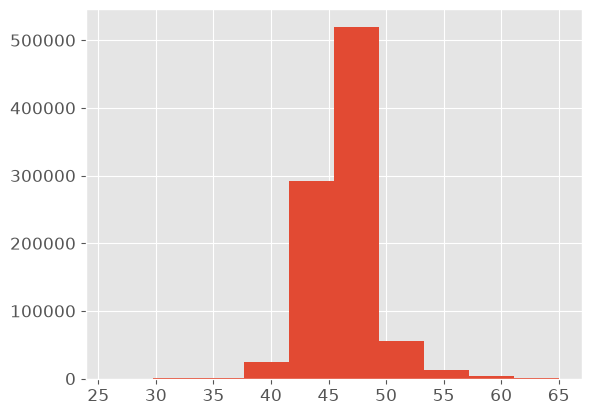

In [55]:
plt.hist(df_1.Target)

<Axes: >

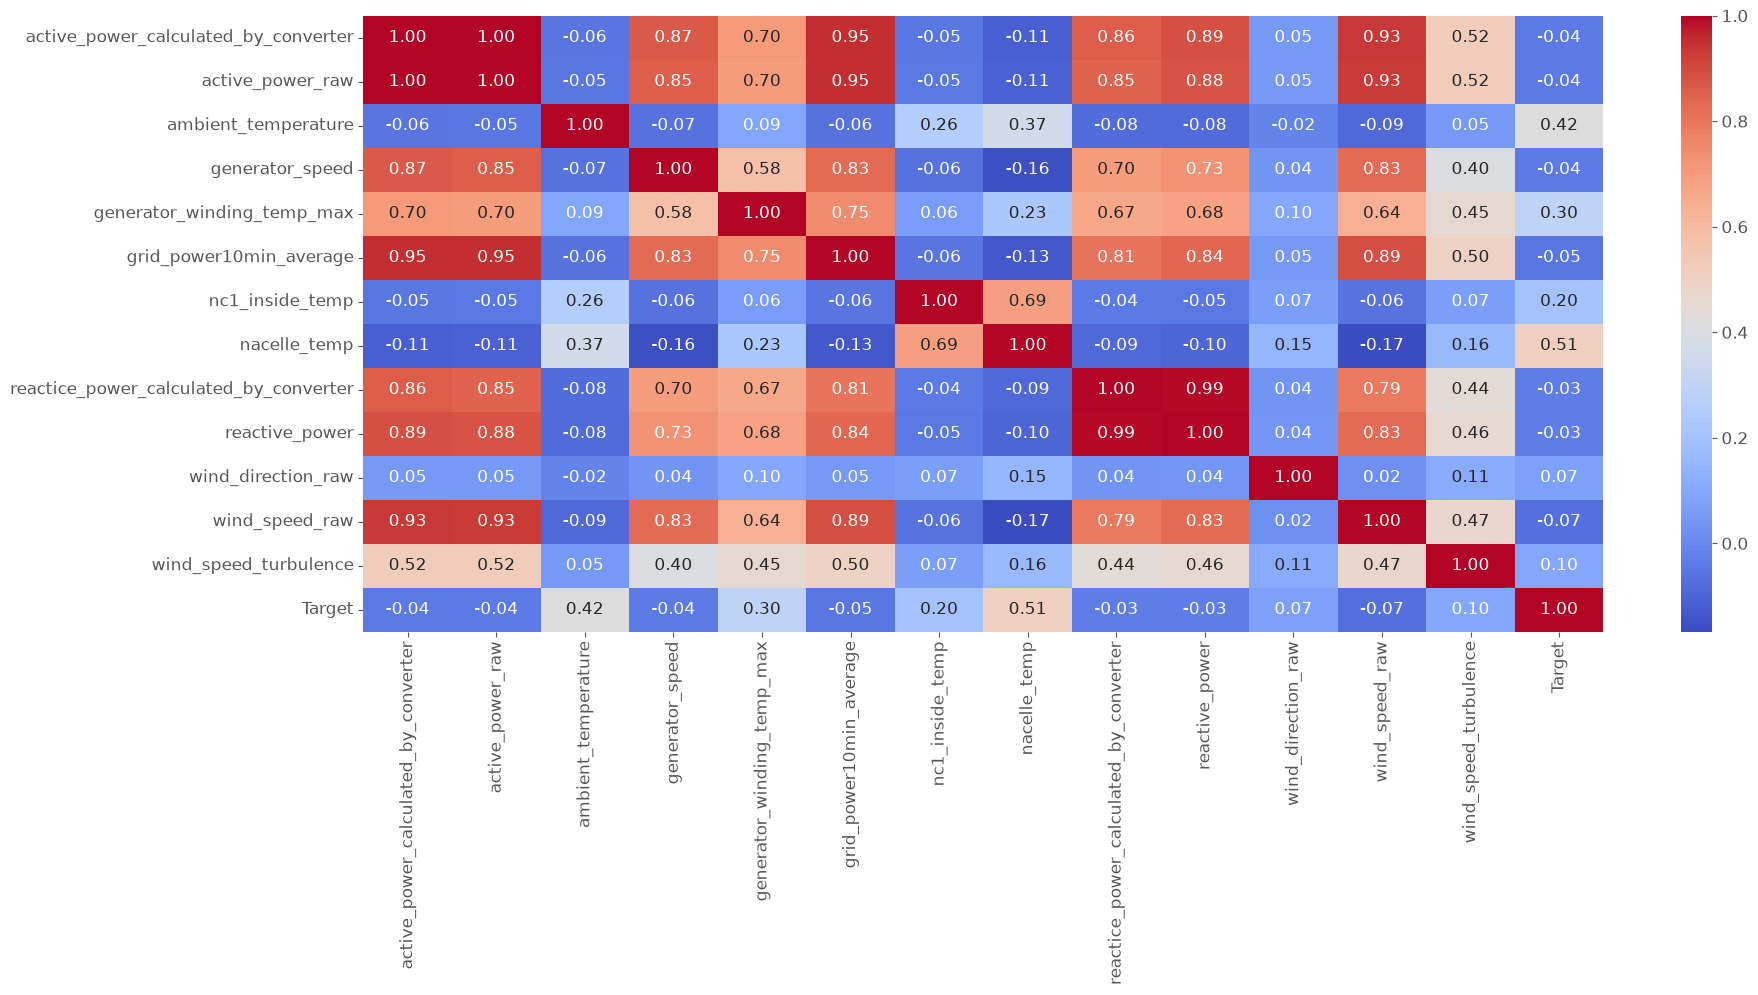

In [56]:
plt.figure(figsize=(20, 8))
sns.heatmap(df_1.corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f', square=False)

In [57]:
# drop_cols = [
#     'active_power_calculated_by_converter',
#     'grid_power10min_average',
#     'reactice_power_calculated_by_converter'
# ]

#df_1.drop(columns=drop_cols, inplace=True) ## Wind power is important so 

In [58]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif(df, exclude_columns=None):
 
    if exclude_columns is None:
        exclude_columns = []

    numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
    check_vifs = [col for col in numeric_columns if col not in exclude_columns]

    # Drop rows with NaNs to avoid errors/unreliable VIF values
    df_check = df[check_vifs].dropna()

    vif = pd.DataFrame()
    vif["Features"] = check_vifs
    vif["VIF"] = [
        variance_inflation_factor(df_check.values, i)
        for i in range(len(check_vifs))
    ]

    return vif.sort_values("VIF", ascending=False).reset_index(drop=True)

In [59]:
vif_result = compute_vif(df_1, exclude_columns=['Target'])
print(vif_result)

#After inspecting, drop the worst offender(s) and recompute
vif_result2 = compute_vif(df_1, exclude_columns=['Target', 'active_power_calculated_by_converter'])
print(vif_result2)


vif_result3 = compute_vif(df_1, exclude_columns=['Target', 'active_power_calculated_by_converter',
'reactive_power'])
print(vif_result3)

vif_result4 = compute_vif(df_1, exclude_columns=['Target', 'active_power_calculated_by_converter',
'reactive_power', 'active_power_raw'])
print(vif_result4)

vif_result5 = compute_vif(df_1, exclude_columns=['Target', 'active_power_calculated_by_converter',
'reactive_power', 'active_power_raw', 'grid_power10min_average'])
print(vif_result5)


                                  Features         VIF
0     active_power_calculated_by_converter  192.293479
1                         active_power_raw  163.752729
2                           reactive_power  136.180215
3   reactice_power_calculated_by_converter  109.041743
4                  grid_power10min_average   14.060386
5                           wind_speed_raw    8.616788
6                          generator_speed    4.549658
7               generator_winding_temp_max    3.594684
8                             nacelle_temp    3.267704
9                          nc1_inside_temp    2.197839
10                   wind_speed_turbulence    1.500463
11                     ambient_temperature    1.177642
12                      wind_direction_raw    1.043331
                                  Features         VIF
0                           reactive_power  135.477537
1   reactice_power_calculated_by_converter  106.616776
2                         active_power_raw   22.306130
3         

In [ ]:
# convert the data type of timestamp from object to date time
df_1['timestamp'] = pd.to_datetime(df_1['timestamp'])

df_1['hour'] = df_1['timestamp'].dt.hour
df_1['month'] = df_1['timestamp'].dt.month


In [61]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_1['turbine_id'] = le.fit_transform(df_1['turbine_id'])

In [62]:
df_1

,timestamp,active_power_calculated_by_converter,active_power_raw,ambient_temperature,generator_speed,generator_winding_temp_max,grid_power10min_average,nc1_inside_temp,nacelle_temp,reactice_power_calculated_by_converter,reactive_power,wind_direction_raw,wind_speed_raw,wind_speed_turbulence,turbine_id,Target,hour
0,2021-02-19 20:18:00,816.636759,834.917206,31.694380,1159.616602,65.954214,917.897085,31.881972,31.504713,141.457644,165.501518,280.864782,7.057000,0.544082,4,47.582787,20
1,2021-04-27 04:55:00,419.107829,421.050873,12.894948,928.747996,59.571319,445.554250,32.423705,32.755770,89.186457,113.835236,299.552460,5.474937,0.469031,12,46.070328,4
2,2021-01-25 06:26:00,1303.530558,1337.566142,16.648388,1201.219775,61.270498,1364.716003,11.446849,18.332985,230.622309,281.452253,84.960106,8.092457,0.622318,3,39.989236,6
3,2021-10-30 03:47:00,61.494872,53.481008,28.388141,769.806122,40.674348,14.324897,34.253204,32.662889,66.211015,75.017531,87.261119,4.071032,0.760719,10,46.056587,3
4,2021-03-15 00:39:00,593.514364,611.659108,31.519527,1046.916768,64.341763,599.020172,32.405586,31.466387,137.163938,160.202421,313.724818,6.357943,0.346068,0,54.346095,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
909599,2021-04-25 19:12:00,929.101908,948.441905,32.736076,1187.303192,83.187140,1343.320577,32.291391,35.152280,152.216446,191.088800,189.901812,7.155343,1.028960,7,50.768675,19
909600,2021-02-20 17:37:00,100.730526,88.694599,30.540500,770.245593,56.235497,177.620552,30.434302,29.932141,85.353107,96.621675,93.417590,4.121607,0.595874,11,44.234821,17
909601,2021-10-22 14:18:00,1120.915965,1165.016907,30.901129,1170.456860,62.942943,873.414622,30.491818,33.085164,42.820210,74.111173,230.988398,8.551669,0.951241,10,46.942486,14
909602,2021-02-08 22:03:00,123.444564,116.066919,32.697933,770.190796,57.245207,95.865704,32.338824,31.525384,86.549094,97.470984,65.408801,4.324064,0.247335,15,46.392221,22


In [ ]:
drop_cols = ['active_power_calculated_by_converter',
'reactive_power', 'active_power_raw', 'grid_power10min_average']
    
df_1.drop(columns=drop_cols,inplace=True)    

In [16]:
X = df_1.drop(columns=['Target'])
y = df_1['Target']

In [17]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (909604, 13)
y shape: (909604,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (727683, 13)
Testing shape: (181921, 13)


In [64]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(X_train, y_train)
y_pred_LR = LR.predict(X_test)

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    # min_samples_split=5,
    # min_samples_leaf=2,
    # max_features=1.0,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [ ]:
#!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 3.3 MB/s  0:00:01 eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [21]:
from sklearn.linear_model import  ElasticNetCV

elastic_net_cv = ElasticNetCV(cv=5, random_state=1)

elastic_net_cv.fit(X_train, y_train)

print(f'Best Alpha: {elastic_net_cv.alpha_}')
print(f'Best L1 Ratio:{elastic_net_cv.l1_ratio_}')

y_pred_elastic_net = elastic_net_cv.predict(X_test)


Best Alpha: 0.12351516104200724
Best L1 Ratio:0.5


In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=10,
    objective='reg:squarederror',
    random_state=42
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

In [25]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(loss='squared_error',
                                learning_rate=0.1,
                                n_estimators=100,
                                max_depth = 5, 
                                random_state = 42,
                                max_features = None)

gbr.fit(X_train, y_train)

y_pred_gbr = gbr.predict(X_test)

In [65]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

results = []

models = {
    'Linear Regression': y_pred_LR,
    'Random Forest Regressor': y_pred_rf,
    'XGBoostRegressor': y_pred_xgb,
    'ElasticNetCV': y_pred_elastic_net,
    'GradientBoostingRegressor': y_pred_gbr
}

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                       Model     MAE    RMSE  R2 Score
0          Linear Regression  1.3942  1.9773    0.4275
1    Random Forest Regressor  1.3498  1.9456    0.4457
2           XGBoostRegressor  0.8393  1.2547    0.7695
3               ElasticNetCV  1.3962  1.9795    0.4262
4  GradientBoostingRegressor  1.1259  1.6410    0.6057
